# LoomIQ 04b · Recommendations (Optimization)

When the model says a line will miss its target, **what should the supervisor do?**

This notebook uses Google OR-Tools to recommend the best mix of **moving operators** and **adding overtime**. Reusable code: `src/loomiq/optimization/recommender.py`.

## Goals

1. Turn productivity into **pieces**, so shortfalls are easy to understand
2. Justify the assumptions used when no live figure is available
3. Recommend actions for one real day and check that they follow the factory rules
4. Show the trade-offs: what if overtime or moves are limited?
5. Run it on every test day and be honest about the limits

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from loomiq.data.clean import load_clean_productivity
from loomiq.features.build_features import build_feature_table
from loomiq.models.predict import load_model
from loomiq.models.train_productivity import time_based_split
from loomiq.optimization import recommender as rec
from loomiq.utils.plotting import DEPARTMENT_COLORS, NEUTRAL, TEXT_SECONDARY, apply_style, save_figure

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

df = load_clean_productivity()
bundle = load_model()
settings = rec.get_settings()
train_df, test_df = time_based_split(df, 0.2)

## 1. From productivity to pieces

In this dataset productivity = (pieces × SMV) / available minutes. Turned around:

$$\text{pieces} = \frac{\text{productivity} \times \text{available minutes}}{\text{SMV}}$$

with **available minutes = workers × 480 (8-hour shift) + planned overtime minutes**.

Example: a finishing line of 8 workers with an SMV of 4.0 and a target of 0.75 has 8 × 480 = 3,840 minutes, so a target of **0.75 × 3,840 / 4.0 = 720 pieces**. If it is expected to run at 0.60, it makes 576 pieces: **144 pieces short**.

## 2. Assumptions: expected productivity

During a real shift, the simulator (Module 4) will give each line's **live** expected productivity. For past days we only have the model's yes/no prediction, so we assume a line ends with the **typical gap** for its department:

In [2]:
history = build_feature_table(train_df)
typical = history.pivot_table(index="department", columns="met_target", values="productivity_gap",
                              aggfunc="median", observed=True).rename(columns={0: "missed", 1: "met"})
typical.round(3)

met_target,missed,met
department,,
sewing,-0.143,0.001
finishing,-0.152,0.146


These medians are stored in `configs/config.yaml` (`optimization.typical_gap`).

- A line that **misses** usually ends about **0.14 to 0.15 below** target in both departments.
- A **sewing** line that meets its target lands **exactly on it** (notebook 02), so it has **no spare capacity** to lend.
- A **finishing** line that meets its target is about **0.15 above** it, so it **can lend operators**.

**Prediction:** the optimizer should rebalance operators in finishing and use overtime in sewing. Let's check.

## 3. One real day: 4 March 2015

A day from the test weeks, which the model never saw during training.

In [3]:
day = df[df["date"] == "2015-03-04"]
plan = rec.recommend_for_rows(day, bundle)
print(f"{len(day)} lines | solver: {plan.status}")
print(f"Expected pieces short: {plan.pieces_short_before:,.0f} before -> {plan.pieces_short_after:,.0f} after "
      f"({plan.pieces_recovered / plan.pieces_short_before:.0%} recovered)")
rec.plan_to_frame(plan)[["action", "line_id", "source_line_id", "amount", "expected_gain_pieces"]]

21 lines | solver: OPTIMAL
Expected pieces short: 1,450 before -> 66 after (95% recovered)


,action,line_id,source_line_id,amount,expected_gain_pieces
0,move_operators,Finishing 2,Finishing 3,1.0,43.1
1,move_operators,Finishing 9,Finishing 7,1.0,99.3
2,move_operators,Finishing 1,Finishing 7,1.0,67.0
3,move_operators,Finishing 4,Finishing 7,1.0,67.0
4,move_operators,Finishing 5,Finishing 7,1.0,57.4
5,move_operators,Finishing 2,Finishing 7,1.0,43.1
6,add_overtime,Finishing 8,NaN,120.0,135.7
7,add_overtime,Finishing 12,NaN,120.0,152.6
8,add_overtime,Finishing 9,NaN,90.0,149.0
9,add_overtime,Finishing 1,NaN,120.0,134.0


In [4]:
for action in plan.actions[:4]:
    print(f"- {action.reason}")

- Finishing 2 is expected to finish about 185 pieces short. Finishing 3 is about 196 pieces ahead and still meets its target after lending 1 operator(s).
- Finishing 9 is expected to finish about 248 pieces short. Finishing 7 is about 587 pieces ahead and still meets its target after lending 1 operator(s).
- Finishing 1 is expected to finish about 183 pieces short. Finishing 7 is about 587 pieces ahead and still meets its target after lending 1 operator(s).
- Finishing 4 is expected to finish about 183 pieces short. Finishing 7 is about 587 pieces ahead and still meets its target after lending 1 operator(s).


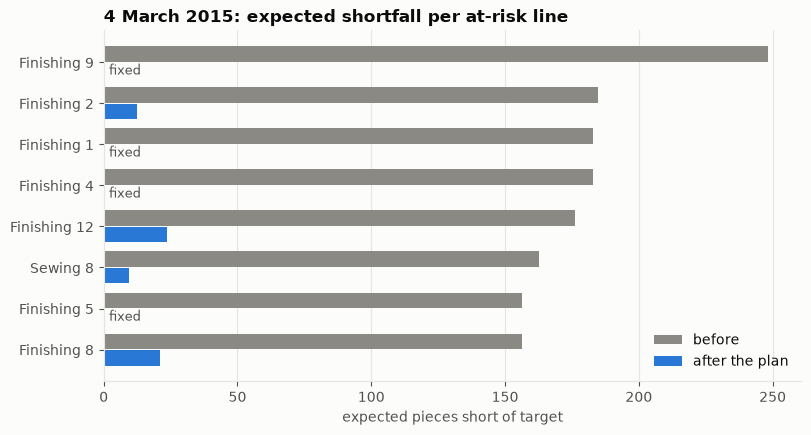

In [5]:
table = plan.lines
at_risk = table[table["shortfall_pieces"] > 0].sort_values("shortfall_pieces")
y = np.arange(len(at_risk))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(at_risk) + 1.2))
ax.barh(y + 0.2, at_risk["shortfall_pieces"], height=0.38, color=NEUTRAL, label="before")
ax.barh(y - 0.2, at_risk["shortfall_pieces_after"], height=0.38,
        color=DEPARTMENT_COLORS["sewing"], label="after the plan")
for pos, after in zip(y, at_risk["shortfall_pieces_after"]):
    if after < 0.5:
        ax.text(2, pos - 0.2, "fixed", va="center", color=TEXT_SECONDARY, fontsize=9)
ax.set_yticks(y, at_risk["line_id"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("expected pieces short of target")
ax.legend(loc="lower right")
ax.set_title("4 March 2015: expected shortfall per at-risk line")
save_figure(fig, "rec_01_one_day")
plt.show()

### Check the factory rules

In [6]:
lenders = table[table["operators_out"] > 0]
checks = {
    "operators moved in == moved out": table["operators_in"].sum() == table["operators_out"].sum(),
    "every lending line still meets its target": bool((lenders["expected_pieces_after"] >= lenders["target_pieces"] - 1e-6).all()),
    "no move between departments": all(
        table.set_index("line_id").at[a.source_line_id, "department"] == table.set_index("line_id").at[a.line_id, "department"]
        for a in plan.actions if a.action == "move_operators"
    ),
    f"overtime <= {settings['max_overtime_minutes_per_line']} min per worker": table["extra_overtime_minutes"].max() <= settings["max_overtime_minutes_per_line"],
    f"<= {settings['max_operators_moved_per_line']} operators in/out per line": table[["operators_in", "operators_out"]].max().max() <= settings["max_operators_moved_per_line"],
}
pd.Series(checks, name="passed").to_frame()

,passed
operators moved in == moved out,True
every lending line still meets its target,True
no move between departments,True
overtime <= 120 min per worker,True
<= 5 operators in/out per line,True


In [7]:
table.groupby("department", observed=True)[["operators_in", "extra_overtime_minutes"]].sum()

,operators_in,extra_overtime_minutes
department,,
sewing,0,120
finishing,6,810


**Findings**
- Exactly as predicted: **finishing** lines lend operators to each other, while **sewing** lines (no spare capacity) only get **overtime**. Finishing lines that are still short after the moves also get overtime.
- One extra operator adds about **40 to 100 pieces** on a small finishing line, depending on its SMV and pace.
- Lines still short after the plan are flagged **"unresolved"**: the manager needs a different fix (adjust the target, split the order, or add people from outside the line pool).
- Every factory rule holds.

## 4. What-if: trade-offs between moves and overtime

Overtime costs money and tires workers, and moving operators disrupts lines. How much does each lever matter?

In [8]:
scenarios = {
    "no help": dict(max_overtime_minutes_per_line=0, max_operators_moved_per_line=0),
    "moves only": dict(max_overtime_minutes_per_line=0),
    "overtime only (max 1 h)": dict(max_operators_moved_per_line=0, max_overtime_minutes_per_line=60),
    "overtime only (max 2 h)": dict(max_operators_moved_per_line=0),
    "both (default)": {},
}
rows = []
for name, overrides in scenarios.items():
    p = rec.recommend_for_rows(day, bundle, **overrides)
    rows.append({
        "scenario": name,
        "pieces short": p.pieces_short_after,
        "operators moved": int(p.lines["operators_in"].sum()),
        "overtime worker-hours": float((p.lines["extra_overtime_minutes"] * p.lines["no_of_workers"]).sum() / 60),
    })
what_if = pd.DataFrame(rows).set_index("scenario")
what_if.round(0)

,pieces short,operators moved,overtime worker-hours
scenario,,,
no help,1450.0,0,0.0
moves only,980.0,6,0.0
overtime only (max 1 h),896.0,0,114.0
overtime only (max 2 h),341.0,0,228.0
both (default),66.0,6,224.0


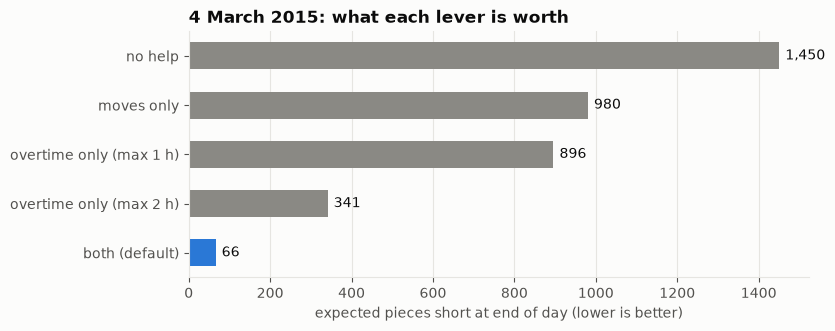

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
order = what_if.index[::-1]
colors = [DEPARTMENT_COLORS["sewing"] if s == "both (default)" else NEUTRAL for s in order]
ax.barh(order, what_if.loc[order, "pieces short"], color=colors, height=0.55)
for i, value in enumerate(what_if.loc[order, "pieces short"]):
    ax.text(value + 15, i, f"{value:,.0f}", va="center")
ax.grid(axis="y", visible=False)
ax.set_xlabel("expected pieces short at end of day (lower is better)")
ax.set_title("4 March 2015: what each lever is worth")
save_figure(fig, "rec_02_what_if")
plt.show()

**Findings**
- **Moves alone** cut the shortfall from 1,450 to 980 pieces. They only help finishing, because sewing has no lines with spare capacity.
- **Overtime alone** (up to 2 hours) gets to 341 pieces, using 228 worker-hours.
- **Combining both** gets to **66 pieces with slightly *less* overtime** (224 worker-hours): moves cover gaps in finishing, so overtime goes where moves can't reach.
- Managers can change these limits in `configs/config.yaml`, or per run, e.g. `recommend_for_rows(day, max_operators_moved_per_line=3)`.

## 5. Every test day

In [10]:
daily = []
for date, rows_for_day in test_df.groupby("date"):
    p = rec.recommend_for_rows(rows_for_day, bundle)
    daily.append({
        "date": date.date(),
        "lines": len(rows_for_day),
        "lines at risk": int((p.lines["shortfall_pieces"] > 0).sum()),
        "pieces short before": p.pieces_short_before,
        "pieces short after": p.pieces_short_after,
        "operators moved": int(p.lines["operators_in"].sum()),
        "lines with overtime": int((p.lines["extra_overtime_minutes"] > 0).sum()),
        "solver": p.status,
    })
daily = pd.DataFrame(daily)
daily["recovered"] = 1 - daily["pieces short after"] / daily["pieces short before"]
daily.style.format({"pieces short before": "{:,.0f}", "pieces short after": "{:,.0f}", "recovered": "{:.0%}"})

,date,lines,lines at risk,pieces short before,pieces short after,operators moved,lines with overtime,solver,recovered
0,2015-02-26,21,10,"2,804",782,4,10,OPTIMAL,72%
1,2015-02-28,21,7,"1,883",108,11,7,OPTIMAL,94%
2,2015-03-01,20,10,"2,297",191,9,10,OPTIMAL,92%
3,2015-03-02,20,2,544,46,5,1,OPTIMAL,91%
4,2015-03-03,22,5,"1,331",200,9,3,OPTIMAL,85%
5,2015-03-04,21,8,"1,450",66,6,8,OPTIMAL,95%
6,2015-03-05,19,11,"2,517",319,2,11,OPTIMAL,87%
7,2015-03-07,19,4,911,38,10,3,OPTIMAL,96%
8,2015-03-08,22,10,"2,300",181,8,10,OPTIMAL,92%
9,2015-03-09,22,7,"1,254",302,2,6,OPTIMAL,76%


In [11]:
totals = daily[["pieces short before", "pieces short after"]].sum()
print(f"Test weeks: {totals['pieces short before']:,.0f} expected pieces short -> {totals['pieces short after']:,.0f} "
      f"after the plans ({1 - totals['pieces short after'] / totals['pieces short before']:.0%} recovered)")
print("Solver status on every day:", daily["solver"].unique().tolist())

Test weeks: 22,127 expected pieces short -> 2,618 after the plans (88% recovered)
Solver status on every day: ['OPTIMAL']


## 6. Honest limits

- **The plan is only as good as the prediction.** In the test weeks, about 43% of "will miss" warnings were correct (notebook 04). Some recommended actions would go to lines that were actually fine. That is why the dashboard should present these as **suggestions for a supervisor to confirm**, not automatic orders.
- **Expected output uses typical gaps**, not live data. With hourly data from the simulator, each line's real pace replaces this assumption.
- **Simplifications:** a moved operator is assumed to work at the receiving line's pace for the full shift (no time lost walking over or learning the operation), and overtime applies to the whole line.
- **Costs are tie-breakers**, not real money. They stop the solver from making pointless changes. With real wage data, they could become actual costs.

## Summary

| | Result |
|---|---|
| Method | OR-Tools CP-SAT: choose operator moves and overtime to minimise pieces short |
| Rules | lenders keep their target, same-department moves only, caps on moves and overtime |
| 4 March 2015 | expected shortfall cut from 1,450 to 66 pieces (95%) |
| All 12 test days | 22,127 expected pieces short cut to 2,618 (88%) |
| Pattern found | finishing rebalances operators; sewing needs overtime (no spare capacity) |
| Solver | proven optimal plan on every test day |

**Next:** Module 3, fabric defect detection.